###  comparison among existing segmentation models
unet, deeplabv3+, hrnet

In [ ]:
import pandas as pd
import seaborn as sns
from glob import glob
import rasterio as rio 
import matplotlib.pyplot as plt
from processing import config
from pyrsimg import metrics_segm, imsShow 


In [5]:
dir_result_1 = 'data/result/val_pred_256/'
dir_result_2 = 'data/result/val_pred_1024to256/'
# dir_result_2 = 'data/result/val_pred_1024/'
paths_val_scene = config.paths_val_scene
paths_val_truth = config.paths_val_truth
paths_val_result_1 = sorted(glob(dir_result_1 + '*.tif'))
paths_val_result_2 = sorted(glob(dir_result_2 + '*.tif'))
print(len(config.paths_val_scene))   


43


In [6]:
## read data
scenes, results_1, results_2, truths = [], [], [], []
for path_scene, path_result_1, path_result_2, path_truth in zip(paths_val_scene, paths_val_result_1, paths_val_result_2,  paths_val_truth):
    with rio.open(path_scene) as scene_rio:
        scene_arr = scene_rio.read()
        scene_arr = scene_arr.transpose((1, 2, 0))   ## (H,W,C)
        scenes.append(scene_arr)
    with rio.open(path_result_1) as result_1_rio:
        result_arr_1 = result_1_rio.read(1)
        results_1.append(result_arr_1)
    with rio.open(path_result_2) as result_2_rio:
        result_2_arr = result_2_rio.read(1)
        results_2.append(result_2_arr)
    with rio.open(path_truth) as truth_rio:
        truth_arr = truth_rio.read(1)                ## (H,W)
        profile_truth = truth_rio.profile
        truths.append(truth_arr)



In [7]:
metrics_scenes = {}
for i, (result_2_arr, truth_arr) in enumerate(zip(results_2, truths)):
    metrics_sg = metrics_segm(cla_map=result_2_arr, truth_map=truth_arr, 
                              class_labels=[0, 1], mean_mode=True)
    metrics = {'miou': metrics_sg.iou['labels_mean'], 
                'oa': metrics_sg.oa,
                'precision': metrics_sg.precision['labels_mean'],
                'recall': metrics_sg.recall['labels_mean']}
    metrics_scenes[paths_val_truth[i].split('/')[-1].split('.')[0]] = metrics
len(metrics_scenes)    
df_metrics_scenes = pd.DataFrame.from_dict(metrics_scenes, orient='index')
df_metrics_scenes

,miou,oa,precision,recall
S2A_L2A_20190125_N0211_R034_S1_truth,0.938263,0.972759,0.970048,0.966022
S2A_L2A_20190206_N0211_R067_S3_truth,0.822346,0.967748,0.937181,0.862870
S2A_L2A_20190318_N0211_R061_S2_truth,0.911894,0.987172,0.953666,0.951007
S2A_L2A_20190429_N0211_R096_S1_truth,0.945034,0.984443,0.982199,0.961301
S2A_L2A_20190508_N0212_R078_S3_truth,0.915403,0.988050,0.970949,0.939099
S2A_L2A_20190716_N0213_R063_S2_truth,0.878768,0.968024,0.964410,0.907697
S2A_L2A_20190725_N0213_R054_S1_truth,0.990615,0.996498,0.996032,0.994532
S2A_L2A_20190811_N0213_R013_S2_truth,0.942038,0.983599,0.963697,0.976059
S2A_L2A_20190817_N0213_R089_S4_truth,0.727170,0.960282,0.845531,0.799973
S2B_L2A_20181226_N0211_R102_S2_truth,0.952748,0.977330,0.980256,0.971893


scene: S2A_L2A_20190716_N0213_R063_S2.tif,       miou: 0.8788


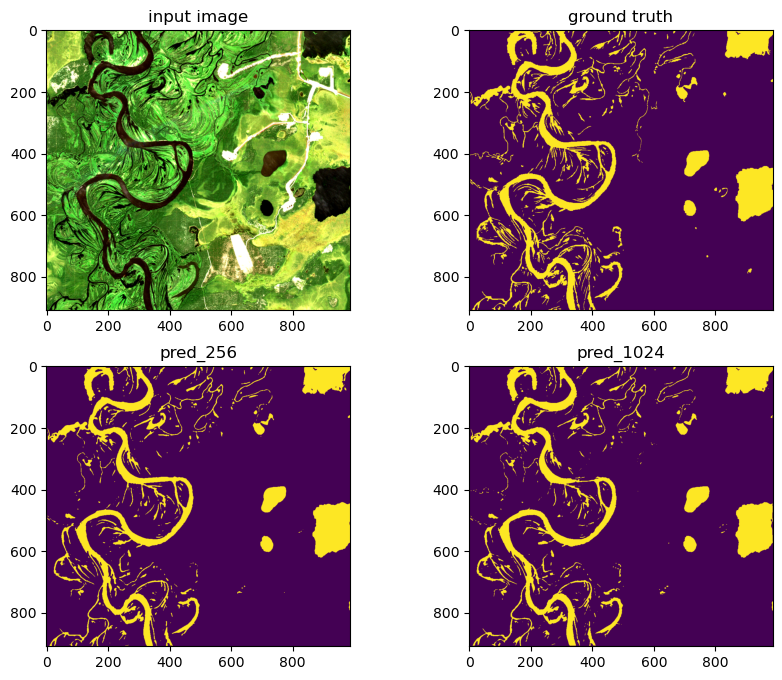

In [8]:
### show the results
i = 5
print(f'scene: {paths_val_scene[i].split("/")[-1]}, \
      miou: {df_metrics_scenes.iloc[i]["miou"]:.4f}')
imsShow(img_list = [scenes[i], truths[i], results_1[i], results_2[i]], 
            clip_list=[5, 0, 0, 0], 
            img_name_list = ['input image', 'ground truth', 'pred_256', 'pred_1024'],
            row=2, 
            col=2,
            figsize=(10, 8)
            );

